# 강판 표면 결함 분류 (단순화 버전)

원래 노트북의 흐름은 그대로 두고, 직접 만든 클래스와 복잡한 함수를 빼서 위에서 아래로 차례대로 읽히게 정리한 버전입니다.

1. 데이터 불러오기 → 2. 열 정리 → 3. 데이터 살펴보기 → 4. 학습/테스트 나누기
5. 모델 4개 튜닝 → 6. 상위 2개 앙상블 → 7. 테스트 평가 → 8. 오분류 확인
9. 변수 중요도 → 10. 저장 및 예측 → 11. 성능 개선 실험

In [1]:
# ============================================================
# 0. 라이브러리 불러오기 및 기본 설정
# ============================================================

import numpy as np                  # 숫자 계산
import pandas as pd                 # 표(데이터프레임) 다루기
import matplotlib.pyplot as plt     # 그래프 그리기
import joblib                       # 모델 파일로 저장 / 불러오기
import warnings
warnings.filterwarnings("ignore")   # 경고 메시지 숨기기

from scipy.stats import chi2_contingency                 # 카이제곱 검정
from sklearn.base import clone                           # 모델 설정만 복사 (학습 전 상태)
from sklearn.model_selection import train_test_split     # 학습/테스트 나누기
from sklearn.model_selection import StratifiedKFold      # 클래스 비율 유지 교차검증
from sklearn.model_selection import RepeatedStratifiedKFold  # 교차검증 여러 번 반복
from sklearn.model_selection import RandomizedSearchCV   # 하이퍼파라미터 무작위 탐색
from sklearn.model_selection import cross_val_score      # 교차검증 점수 계산
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import VotingClassifier            # 여러 모델 확률 평균(앙상블)
from sklearn.inspection import permutation_importance    # 변수 중요도
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 폰트 (맥은 "AppleGothic")
plt.rcParams["axes.unicode_minus"] = False      # 그래프에서 마이너스(-) 깨짐 방지
pd.set_option("display.max_columns", None)      # 표의 모든 열 보이기

RANDOM_STATE = 42   # 이 숫자를 고정하면 실행할 때마다 같은 결과가 나온다
N_ITER = 20         # 모델마다 시험해 볼 하이퍼파라미터 조합 수 (오래 걸리면 줄이기)

In [2]:
# ============================================================
# 1. 데이터 불러오기
# ============================================================

df = pd.read_csv("steel_plates_faults.csv")       # CSV 파일 읽기

print("데이터 크기:", df.shape)                    # (행 수, 열 수)
print("결측치 개수:", df.isna().sum().sum())       # 빈 칸 개수 (0이면 정상)
print("중복 행 개수:", df.duplicated().sum())      # 완전히 같은 행 개수
df.head()                                         # 앞 5행 보기

데이터 크기: (1941, 34)
결측치 개수: 0
중복 행 개수: 0


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [3]:
# ============================================================
# 2. 열 정리 - 원-핫 열을 하나의 열로 합치기
# ============================================================

# 강종을 나타내는 2개 열, 결함 종류를 나타내는 7개 열
steel_cols = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
fault_cols = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]

# 각 행에 강종과 결함이 정확히 하나씩만 표시돼 있는지 확인 (가로 합이 1이어야 함)
print("강종이 하나로 정해진 행만 있는가:", (df[steel_cols].sum(axis=1) == 1).all())
print("결함이 하나로 정해진 행만 있는가:", (df[fault_cols].sum(axis=1) == 1).all())

# 결함 7개 열 → 값이 1인 열의 이름을 꺼내서 'Fault_Type' 열 하나로 만든다
df["Fault_Type"] = df[fault_cols].idxmax(axis=1)

# 강종 2개 열 → A300이면 0, A400이면 1 ('TypeOfSteel_A400' 값과 같다)
df["Steel_Type"] = df["TypeOfSteel_A400"]

df[["Steel_Type", "Fault_Type"]].head()

강종이 하나로 정해진 행만 있는가: True
결함이 하나로 정해진 행만 있는가: True


,Steel_Type,Fault_Type
0,0,Pastry
1,0,Pastry
2,0,Pastry
3,1,Pastry
4,1,Pastry


In [4]:
# ============================================================
# 3. 데이터 살펴보기 - 결함 분포, 강종과 결함의 관계
# ============================================================

# 결함 종류별 개수 (클래스 불균형 확인)
print("[결함 종류별 개수]")
print(df["Fault_Type"].value_counts())

# 결함 종류 × 강종 교차표
table = pd.crosstab(df["Fault_Type"], df["Steel_Type"])
print("\n[결함 종류 × 강종 (0=A300, 1=A400)]")
print(table)

# 카이제곱 검정: 강종과 결함 종류가 서로 관련이 있는가?
chi2, p_value, dof, expected = chi2_contingency(table)

# Cramér's V: 관련성의 세기 (0 = 관련 없음, 1 = 완전히 관련)
cramers_v = np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))

print(f"\n카이제곱 = {chi2:.1f}, p값 = {p_value:.4f}, Cramér's V = {cramers_v:.3f}")

[결함 종류별 개수]
Fault_Type
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

[결함 종류 × 강종 (0=A300, 1=A400)]
Steel_Type      0    1
Fault_Type            
Bumps         279  123
Dirtiness       9   46
K_Scatch        1  390
Other_Faults  266  407
Pastry         49  109
Stains          1   71
Z_Scratch     172   18

카이제곱 = 667.0, p값 = 0.0000, Cramér's V = 0.586


In [5]:
# ============================================================
# 4. 입력(X) / 정답(y) 만들고 학습 80% / 테스트 20% 로 나누기
# ============================================================

# 입력 변수: 원래 원-핫 열과 정답 열을 뺀 나머지 (Steel_Type 은 포함)
X = df.drop(columns=steel_cols + fault_cols + ["Fault_Type"])
y = df["Fault_Type"]                     # 정답: 결함 종류 이름

# stratify=y : 학습/테스트 모두 결함 비율이 원래 데이터와 같게 나눈다
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("학습 데이터:", X_train.shape, "/ 테스트 데이터:", X_test.shape)

# 5-Fold 교차검증 설정: 학습 데이터를 5조각으로 나눠 돌아가며 검증
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

학습 데이터: (1552, 26) / 테스트 데이터: (389, 26)


In [6]:
# ============================================================
# 5-1. 사용할 모델과 시험해 볼 하이퍼파라미터 범위
# ============================================================

models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    "CatBoost": CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0,
                                   allow_writing_files=False),
}

# class_weight="balanced" : 개수가 적은 결함에 가중치를 더 줘서 불균형을 보정
params = {
    "Random Forest": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "LightGBM": {
        "n_estimators": [200, 400, 700, 1000],
        "learning_rate": [0.02, 0.03, 0.05, 0.1],
        "num_leaves": [7, 15, 22, 31],
        "max_depth": [-1, 5, 7, 10],
        "min_child_samples": [5, 10, 20, 33],
        "subsample": [0.6, 0.8, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [0, 0.01, 1, 5],
        "class_weight": [None, "balanced"],
    },
    "CatBoost": {
        "iterations": [300, 500, 700],
        "depth": [4, 5, 6, 7],
        "learning_rate": [0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 7],
        "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
    },
}

In [7]:
# ============================================================
# 5-2. 하이퍼파라미터 튜닝 (학습 데이터 5-Fold 교차검증, Macro F1 기준)
# ============================================================
# Macro F1 : 결함 7종의 F1을 단순 평균. 개수가 적은 결함도 똑같이 중요하게 본다.

best_models = {}    # 모델 이름 → 튜닝된 모델
results = []        # 결과 표를 만들 목록

for name in models:
    print(name, "튜닝 중...")

    search = RandomizedSearchCV(
        models[name],          # 튜닝할 모델
        params[name],          # 시험할 하이퍼파라미터 범위
        n_iter=N_ITER,         # 무작위로 고를 조합 수
        scoring="f1_macro",    # 평가 기준
        cv=cv,                 # 5-Fold 교차검증
        random_state=RANDOM_STATE,
        n_jobs=-1,             # CPU 코어 모두 사용
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_            # 가장 좋았던 설정의 모델
    results.append([name, search.best_score_, search.best_params_])
    print(f"  CV Macro F1 = {search.best_score_:.4f}")

# 결과를 표로 만들고 점수 높은 순으로 정렬
result_df = pd.DataFrame(results, columns=["모델", "CV Macro F1", "최적 파라미터"])
result_df = result_df.sort_values("CV Macro F1", ascending=False).reset_index(drop=True)
result_df

Random Forest 튜닝 중...
  CV Macro F1 = 0.7958
Extra Trees 튜닝 중...
  CV Macro F1 = 0.8214
LightGBM 튜닝 중...
  CV Macro F1 = 0.8181
CatBoost 튜닝 중...
  CV Macro F1 = 0.8170


,모델,CV Macro F1,최적 파라미터
0,Extra Trees,0.821418,"{'n_estimators': 500, 'min_samples_split': 5, ..."
1,LightGBM,0.818101,"{'subsample_freq': 1, 'subsample': 0.8, 'reg_l..."
2,CatBoost,0.817008,"{'learning_rate': 0.1, 'l2_leaf_reg': 3, 'iter..."
3,Random Forest,0.795775,"{'n_estimators': 500, 'min_samples_split': 2, ..."


In [9]:
# ============================================================
# 6. 상위 2개 모델 앙상블 (소프트 보팅 = 두 모델의 예측 확률 평균)
# ============================================================

from sklearn import set_config
set_config(display="text")

top2 = result_df["모델"].head(2).tolist()      # 점수가 가장 높은 모델 2개 이름
print("앙상블에 쓸 모델:", top2)

ensemble = VotingClassifier(
    estimators=[(name, best_models[name]) for name in top2],   # (이름, 모델) 목록
    voting="soft",                                             # 확률을 평균해서 결정
)

# 앙상블도 같은 교차검증으로 점수를 확인 (단일 모델보다 좋은지 비교)
ens_scores = cross_val_score(ensemble, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"앙상블 CV Macro F1 = {ens_scores.mean():.4f} ± {ens_scores.std():.4f}")

# 학습 데이터 전체로 앙상블 학습
ensemble.fit(X_train, y_train)

앙상블에 쓸 모델: ['Extra Trees', 'LightGBM']
앙상블 CV Macro F1 = 0.8198 ± 0.0197


VotingClassifier(estimators=[('Extra Trees',
                              ExtraTreesClassifier(class_weight='balanced_subsample',
                                                   max_features=0.8,
                                                   min_samples_split=5,
                                                   n_estimators=500,
                                                   random_state=42)),
                             ('LightGBM',
                              LGBMClassifier(class_weight='balanced',
                                             max_depth=5, n_estimators=700,
                                             num_leaves=22, random_state=42,
                                             reg_lambda=0.01, subsample=0.8,
                                             subsample_freq=1, verbose=-1))],
                 voting='soft')

In [10]:
# ============================================================
# 7. 테스트 데이터로 최종 평가 (테스트는 여기서 한 번만 사용)
# ============================================================

y_pred = ensemble.predict(X_test)      # 테스트 데이터 예측

print("정확도(Accuracy):", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1        :", round(f1_score(y_test, y_pred, average="macro"), 4))

# 부트스트랩 95% 신뢰구간
# 테스트 데이터를 복원 추출로 1000번 다시 뽑아 점수가 얼마나 흔들리는지 확인
rng = np.random.default_rng(RANDOM_STATE)
y_test_arr = y_test.to_numpy()          # 인덱스 없이 값만 꺼내기
boot_scores = []
for i in range(1000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))   # 무작위로 행 번호 뽑기
    boot_scores.append(f1_score(y_test_arr[idx], y_pred[idx], average="macro"))

low, high = np.percentile(boot_scores, [2.5, 97.5])
print(f"Macro F1 95% 신뢰구간: [{low:.3f}, {high:.3f}]")

# 결함 종류별 정밀도 / 재현율 / F1
print(classification_report(y_test, y_pred, labels=fault_cols, digits=4))

정확도(Accuracy): 0.7969
Macro F1        : 0.8092
Macro F1 95% 신뢰구간: [0.759, 0.851]
              precision    recall  f1-score   support

      Pastry     0.5429    0.5938    0.5672        32
   Z_Scratch     0.9722    0.9211    0.9459        38
    K_Scatch     0.9733    0.9359    0.9542        78
      Stains     0.8571    0.8571    0.8571        14
   Dirtiness     0.8333    0.9091    0.8696        11
       Bumps     0.7500    0.6667    0.7059        81
Other_Faults     0.7379    0.7926    0.7643       135

    accuracy                         0.7969       389
   macro avg     0.8095    0.8109    0.8092       389
weighted avg     0.8015    0.7969    0.7981       389



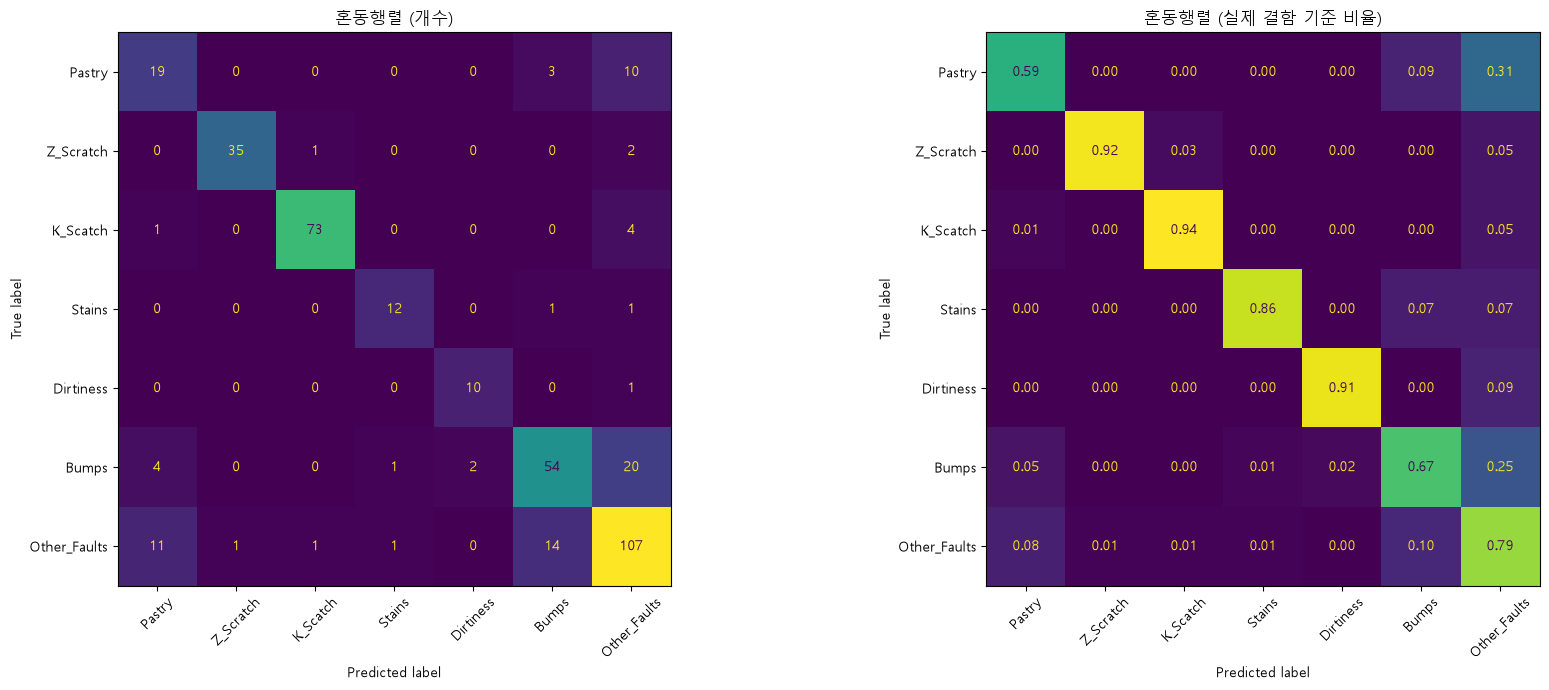

In [11]:
# ============================================================
# 8-1. 혼동행렬 - 어떤 결함을 어떤 결함으로 헷갈리는지
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 왼쪽: 개수
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=fault_cols, ax=axes[0],
    xticks_rotation=45, colorbar=False)
axes[0].set_title("혼동행렬 (개수)")

# 오른쪽: 실제 결함 기준 비율 (한 줄의 합 = 1)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=fault_cols, normalize="true", values_format=".2f",
    ax=axes[1], xticks_rotation=45, colorbar=False)
axes[1].set_title("혼동행렬 (실제 결함 기준 비율)")

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# 8-2. 오분류 행 뽑기
# ============================================================

proba = ensemble.predict_proba(X_test)      # 결함별 예측 확률 (행마다 합 = 1)

# 테스트 결과 표: 실제 결함, 예측 결함, 확신도(가장 높은 확률)
test_result = pd.DataFrame({
    "실제": y_test,
    "예측": y_pred,
    "확신도": proba.max(axis=1),
}, index=X_test.index)              # 인덱스 = 원본 데이터의 행 번호

# 실제와 예측이 다른 행만 골라내기
wrong = test_result[test_result["실제"] != test_result["예측"]]
print(f"오분류: {len(wrong)}개 / {len(test_result)}개 ({len(wrong) / len(test_result):.2%})")

# 자주 헷갈린 조합 (실제 → 예측)
print("\n[자주 헷갈린 조합]")
print(wrong.groupby(["실제", "예측"]).size().sort_values(ascending=False).head(10))

# 높은 확신으로 틀린 행 (라벨이 잘못됐을 수도 있으니 다시 확인해 볼 후보)
print("\n[확신도 높은 오분류 상위 10개]")
display(wrong.sort_values("확신도", ascending=False).head(10))

# 오분류 행 + 원본 열 전체를 파일로 저장 (엑셀에서 열 수 있게 utf-8-sig)
wrong.join(df).to_csv("misclassified_rows.csv", encoding="utf-8-sig")

오분류: 79개 / 389개 (20.31%)

[자주 헷갈린 조합]
실제            예측          
Bumps         Other_Faults    20
Other_Faults  Bumps           14
              Pastry          11
Pastry        Other_Faults    10
K_Scatch      Other_Faults     4
Bumps         Pastry           4
Pastry        Bumps            3
Bumps         Dirtiness        2
Z_Scratch     Other_Faults     2
Dirtiness     Other_Faults     1
dtype: int64

[확신도 높은 오분류 상위 10개]


,실제,예측,확신도
1277,Other_Faults,K_Scatch,0.999837
1035,Bumps,Other_Faults,0.947156
1196,Bumps,Other_Faults,0.914245
1661,Other_Faults,Bumps,0.913026
144,Pastry,Bumps,0.890507
1267,Bumps,Other_Faults,0.890199
1636,Other_Faults,Bumps,0.879281
1125,Bumps,Other_Faults,0.870098
816,Dirtiness,Other_Faults,0.869886
987,Bumps,Pastry,0.858707


,변수,중요도,표준편차
10,Length_of_Conveyer,0.095387,0.017184
11,Steel_Plate_Thickness,0.050452,0.009925
25,Steel_Type,0.048804,0.008819
12,Edges_Index,0.011959,0.006976
15,Outside_X_Index,0.008169,0.005608
8,Minimum_of_Luminosity,0.006746,0.008476
17,Edges_Y_Index,0.005084,0.009957
7,Sum_of_Luminosity,0.002972,0.003510
16,Edges_X_Index,0.002351,0.006655
2,Y_Minimum,0.001971,0.007973


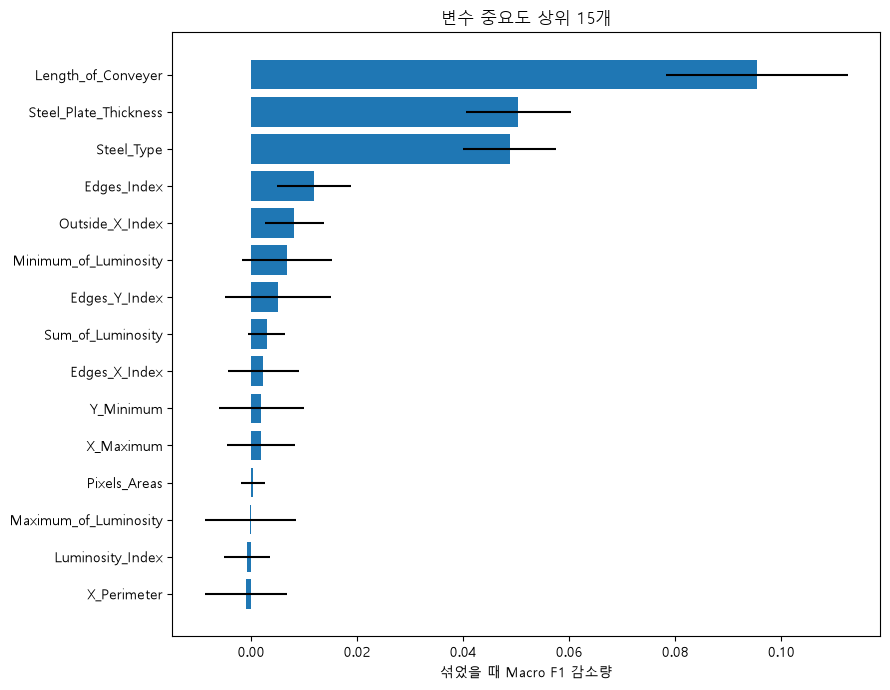

In [13]:
# ============================================================
# 9. 변수 중요도 (Permutation Importance)
# ============================================================
# 변수 하나의 값을 무작위로 섞었을 때 Macro F1이 얼마나 떨어지는지 측정.
# 많이 떨어질수록 모델이 그 변수에 많이 의존한다는 뜻.

perm = permutation_importance(ensemble, X_test, y_test, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)

importance = pd.DataFrame({
    "변수": X.columns,
    "중요도": perm.importances_mean,     # 20번 섞은 결과의 평균
    "표준편차": perm.importances_std,    # 20번 섞은 결과의 흔들림
}).sort_values("중요도", ascending=False)

display(importance.head(15))

# 상위 15개 막대 그래프 (위에서부터 중요한 순서가 되도록 뒤집어서 그림)
top15 = importance.head(15).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top15["변수"], top15["중요도"], xerr=top15["표준편차"])
plt.xlabel("섞었을 때 Macro F1 감소량")
plt.title("변수 중요도 상위 15개")
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# 10-1. 전체 데이터로 다시 학습하고 파일로 저장
# ============================================================
# 평가는 끝났으니 테스트 데이터까지 합친 전체 데이터로 학습해서 실제 사용할 모델을 만든다.

final_model = clone(ensemble)          # 같은 설정의 학습 전 앙상블
final_model.fit(X, y)                  # 전체 데이터로 학습

joblib.dump({"model": final_model, "columns": X.columns.tolist()},
            "steel_fault_model_simple.joblib")
print("저장 완료: steel_fault_model_simple.joblib")

저장 완료: steel_fault_model_simple.joblib


In [15]:
# ============================================================
# 10-2. 새 데이터 예측 함수
# ============================================================
# 원본 CSV와 같은 형식(TypeOfSteel_A300 / A400 열 포함)의 데이터를 넣으면 된다.

def predict_faults(new_data):
    saved = joblib.load("steel_fault_model_simple.joblib")     # 저장한 모델 불러오기
    model = saved["model"]

    data = new_data.copy()
    data["Steel_Type"] = data["TypeOfSteel_A400"]               # 2번 단계와 같은 처리
    X_new = data[saved["columns"]]                              # 학습 때와 같은 열, 같은 순서

    proba = model.predict_proba(X_new)                          # 결함별 확률
    result = pd.DataFrame(proba, columns=model.classes_, index=new_data.index).round(3)
    result.insert(0, "예측 결함", model.predict(X_new))          # 맨 앞에 예측 결과
    result.insert(1, "확신도", proba.max(axis=1).round(3))
    return result


# 동작 확인 (전체 데이터로 학습한 모델이라 이미 본 데이터 → 성능 확인용 아님)
sample = df.loc[X_test.index[:5]]
demo = predict_faults(sample)
demo.insert(0, "실제 결함", sample["Fault_Type"])
demo

,실제 결함,예측 결함,확신도,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch
1710,Other_Faults,Other_Faults,0.890,0.030,0.005,0.011,0.890,0.051,0.002,0.011
863,Dirtiness,Dirtiness,0.989,0.006,0.989,0.000,0.004,0.001,0.000,0.000
1174,Bumps,Bumps,0.999,0.999,0.000,0.000,0.001,0.000,0.000,0.000
1815,Other_Faults,Other_Faults,0.895,0.054,0.002,0.000,0.895,0.045,0.000,0.004
370,K_Scatch,K_Scatch,0.998,0.000,0.000,0.998,0.001,0.000,0.000,0.000


## 11. 성능 개선 실험

모든 실험은 **학습 데이터에서만** 교차검증(5-Fold × 3회 반복 = 15번)으로 비교합니다. 테스트 데이터는 이미 7번에서 결과를 봤기 때문에 실험 비교에 쓰지 않습니다.

`RepeatedStratifiedKFold`의 `random_state`를 고정했으므로, 실험마다 똑같은 15개 조각으로 나뉩니다. 그래서 같은 조각끼리 점수를 짝지어 비교할 수 있습니다.

**판정 기준:** 기준 모델보다 평균 0.005 이상 높고, 15번 중 10번 이상 나아졌으면 "효과 있음"으로 봅니다.

In [16]:
# ============================================================
# 11-1. 실험 준비 - 기준 모델 점수
# ============================================================

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

base_scores = cross_val_score(ensemble, X_train, y_train, cv=cv_rep,
                              scoring="f1_macro", n_jobs=-1)
print(f"기준 모델: {base_scores.mean():.4f} ± {base_scores.std():.4f}")

experiment_scores = {"기준 모델": base_scores}    # 실험 이름 → 15개 점수


def compare(name, scores):
    """기준 모델과 같은 조각끼리 비교해서 결과를 출력하고 저장"""
    experiment_scores[name] = scores
    diff = scores - base_scores                   # 조각별 점수 차이
    better = (diff > 0).sum()                     # 나아진 조각 수
    print(f"{name:<28} {scores.mean():.4f} | 기준 대비 {diff.mean():+.4f} | "
          f"나아진 조각 {better}/15")

기준 모델: 0.8269 ± 0.0210


,변수,구분력(AUC),Bumps 중앙값,Other 중앙값
0,Square_Index,0.673488,7.500000e-01,0.53925
1,Steel_Type,0.646910,0.000000e+00,1.00000
2,Edges_Y_Index,0.640595,1.000000e+00,0.93585
3,Y_Maximum,0.631791,1.465360e+06,894645.50000
4,Y_Minimum,0.631791,1.465348e+06,894631.50000
5,Empty_Index,0.625676,3.333000e-01,0.42715
6,X_Perimeter,0.616185,1.700000e+01,25.00000
7,Y_Perimeter,0.615725,1.600000e+01,22.00000
8,Edges_Index,0.599379,4.531000e-01,0.33210
9,SigmoidOfAreas,0.588180,3.241000e-01,0.41700


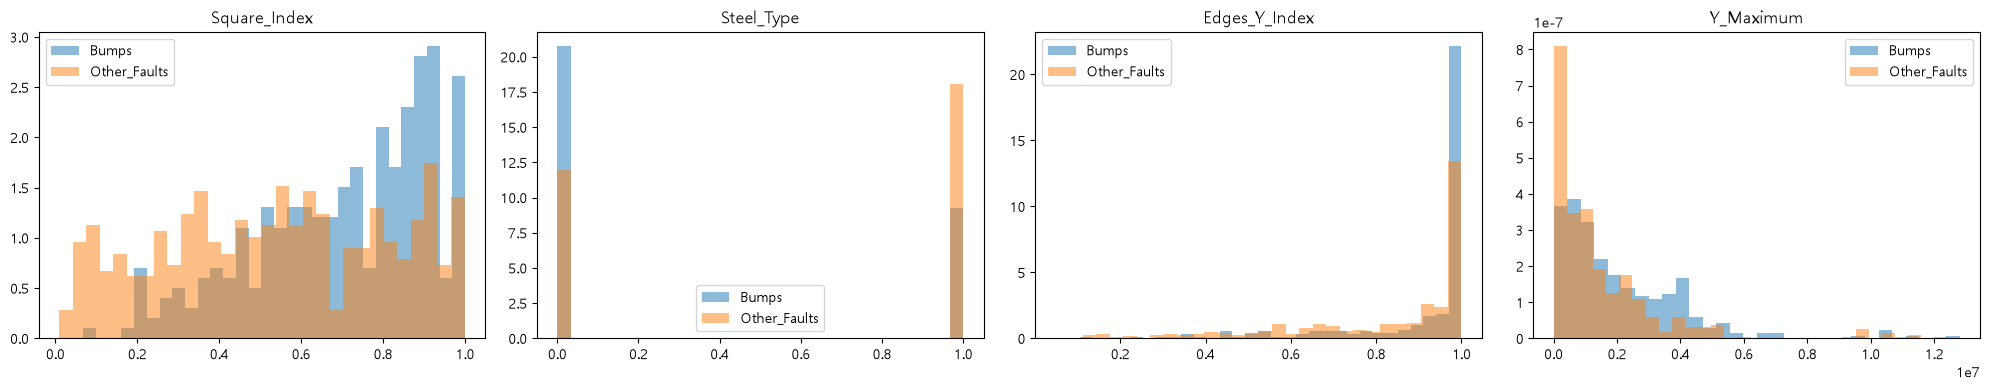

In [17]:
# ============================================================
# 11-2. 가장 많이 헷갈리는 Bumps vs Other_Faults - 어떤 변수가 둘을 가르나?
# ============================================================
# AUC : 변수 하나로 두 결함을 나눌 때의 성능 (0.5 = 못 나눔, 1.0 = 완벽히 나눔)

mask = y_train.isin(["Bumps", "Other_Faults"])     # 두 결함만 고르기
X_bo = X_train[mask]
y_bo = (y_train[mask] == "Bumps").astype(int)       # Bumps = 1, Other_Faults = 0

rows = []
for col in X_bo.columns:
    auc = roc_auc_score(y_bo, X_bo[col])
    auc = max(auc, 1 - auc)                          # 방향과 상관없이 구분력만 보기
    rows.append([col, auc,
                 X_bo.loc[y_bo == 1, col].median(),  # Bumps 의 중앙값
                 X_bo.loc[y_bo == 0, col].median()]) # Other_Faults 의 중앙값

auc_df = pd.DataFrame(rows, columns=["변수", "구분력(AUC)", "Bumps 중앙값", "Other 중앙값"])
auc_df = auc_df.sort_values("구분력(AUC)", ascending=False).reset_index(drop=True)
display(auc_df.head(10))

# 구분력 상위 4개 변수의 분포 비교
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, auc_df["변수"].head(4)):
    ax.hist(X_bo.loc[y_bo == 1, col], bins=30, alpha=0.5, density=True, label="Bumps")
    ax.hist(X_bo.loc[y_bo == 0, col], bins=30, alpha=0.5, density=True, label="Other_Faults")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# 11-3. 규제 강화 실험 - LightGBM 의 reg_lambda 값 바꿔 보기
# ============================================================
# reg_lambda 가 클수록 모델이 학습 데이터를 덜 외운다 (과적합 방지)

if "LightGBM" in top2:
    for value in [1, 5, 20, 50]:
        members = []
        for name in top2:
            model = clone(best_models[name])          # 튜닝된 설정 복사
            if name == "LightGBM":
                model.set_params(reg_lambda=value)    # LightGBM 만 값 변경
            members.append((name, model))

        test_ensemble = VotingClassifier(estimators=members, voting="soft")
        scores = cross_val_score(test_ensemble, X_train, y_train, cv=cv_rep,
                                 scoring="f1_macro", n_jobs=-1)
        compare(f"LightGBM reg_lambda={value}", scores)
else:
    print("LightGBM 이 앙상블에 없어서 건너뜀")

LightGBM reg_lambda=1        0.8210 | 기준 대비 -0.0059 | 나아진 조각 4/15
LightGBM reg_lambda=5        0.8249 | 기준 대비 -0.0020 | 나아진 조각 6/15
LightGBM reg_lambda=20       0.8246 | 기준 대비 -0.0023 | 나아진 조각 5/15
LightGBM reg_lambda=50       0.8218 | 기준 대비 -0.0051 | 나아진 조각 5/15


In [19]:
# ============================================================
# 11-4. 오버샘플링 실험 - 개수가 적은 결함을 150개까지 늘리기
# ============================================================
# 필요 패키지: pip install imbalanced-learn
# imblearn 의 Pipeline 을 쓰면 교차검증의 '학습 조각'에만 오버샘플링이 적용되고
# '검증 조각'에는 적용되지 않는다 (데이터 누수 방지).
# SMOTENC : SMOTE 와 같지만 Steel_Type 같은 범주형 열은 0/1 값을 그대로 유지한다.

from imblearn.over_sampling import SMOTENC, RandomOverSampler
from imblearn.pipeline import Pipeline

# 학습 데이터에서 150개보다 적은 결함만 150개로 늘리도록 설정
counts = y_train.value_counts()
target = {name: 150 for name in counts.index if counts[name] < 150}
print("늘릴 결함:", target)

steel_idx = X_train.columns.get_loc("Steel_Type")    # 범주형 열의 위치

samplers = {
    "RandomOverSampler (복제)": RandomOverSampler(sampling_strategy=target,
                                                 random_state=RANDOM_STATE),
    "SMOTE (보간)": SMOTENC(categorical_features=[steel_idx], sampling_strategy=target,
                            random_state=RANDOM_STATE),
}

for name, sampler in samplers.items():
    pipe = Pipeline([("sampler", sampler), ("model", ensemble)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv_rep,
                             scoring="f1_macro", n_jobs=-1)
    compare(name, scores)

늘릴 결함: {'Pastry': 150, 'Stains': 150, 'Dirtiness': 150}
RandomOverSampler (복제)       0.8212 | 기준 대비 -0.0057 | 나아진 조각 4/15
SMOTE (보간)                   0.8268 | 기준 대비 -0.0001 | 나아진 조각 7/15


In [20]:
# ============================================================
# 11-5. 전체 실험 결과 정리
# ============================================================

rows = []
for name, scores in experiment_scores.items():
    diff = scores - base_scores
    better = (diff > 0).sum()

    # 판정: 평균 +0.005 이상 & 15번 중 10번 이상 나아짐 → 효과 있음
    if name == "기준 모델":
        verdict = "-"
    elif diff.mean() >= 0.005 and better >= 10:
        verdict = "효과 있음"
    elif diff.mean() <= -0.005 and (diff < 0).sum() >= 10:
        verdict = "악화"
    else:
        verdict = "차이 없음"

    rows.append([name, scores.mean(), scores.std(), diff.mean(), f"{better}/15", verdict])

summary = pd.DataFrame(rows, columns=["실험", "Macro F1", "표준편차", "기준 대비",
                                      "나아진 조각", "판정"])
summary = summary.sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(summary.round(4))

summary.to_csv("experiment_summary.csv", index=False, encoding="utf-8-sig")

,실험,Macro F1,표준편차,기준 대비,나아진 조각,판정
0,기준 모델,0.8269,0.0210,0.0000,0/15,-
1,SMOTE (보간),0.8268,0.0174,-0.0001,7/15,차이 없음
2,LightGBM reg_lambda=5,0.8249,0.0186,-0.0020,6/15,차이 없음
3,LightGBM reg_lambda=20,0.8246,0.0197,-0.0023,5/15,차이 없음
4,LightGBM reg_lambda=50,0.8218,0.0207,-0.0051,5/15,악화
5,RandomOverSampler (복제),0.8212,0.0202,-0.0057,4/15,악화
6,LightGBM reg_lambda=1,0.8210,0.0252,-0.0059,4/15,악화
